In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/nigerian-songs.csv")

Text(0.5, 1.0, 'Top genres')

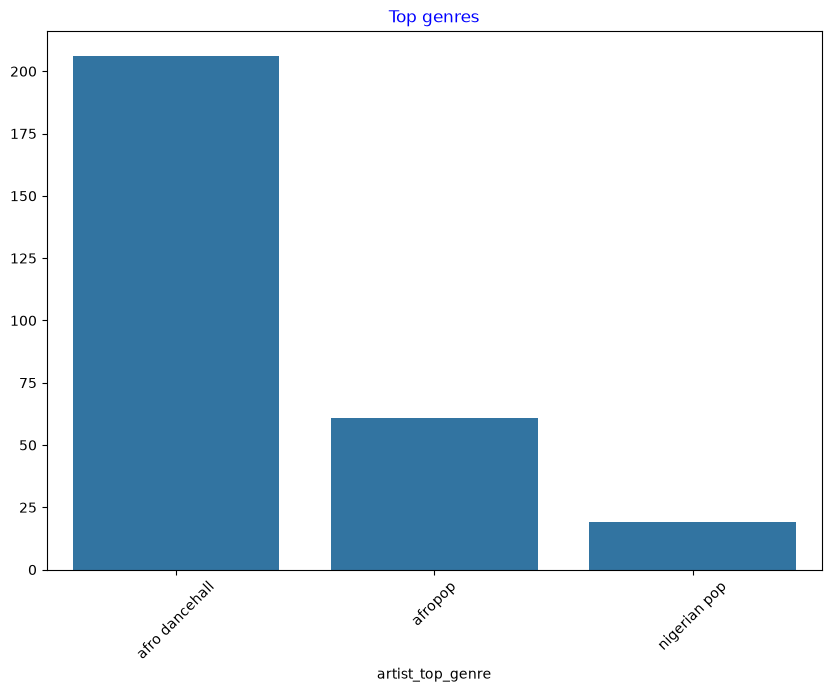

In [2]:
df = df[(df['artist_top_genre'] == 'afro dancehall') | (df['artist_top_genre'] == 'afropop') | (df['artist_top_genre'] == 'nigerian pop')]
df = df[(df['popularity'] > 0)]
top = df['artist_top_genre'].value_counts()
plt.figure(figsize=(10,7))
sns.barplot(x=top.index,y=top.values)
plt.xticks(rotation=45)
plt.title('Top genres',color = 'blue')

<Axes: xlabel='release_date'>

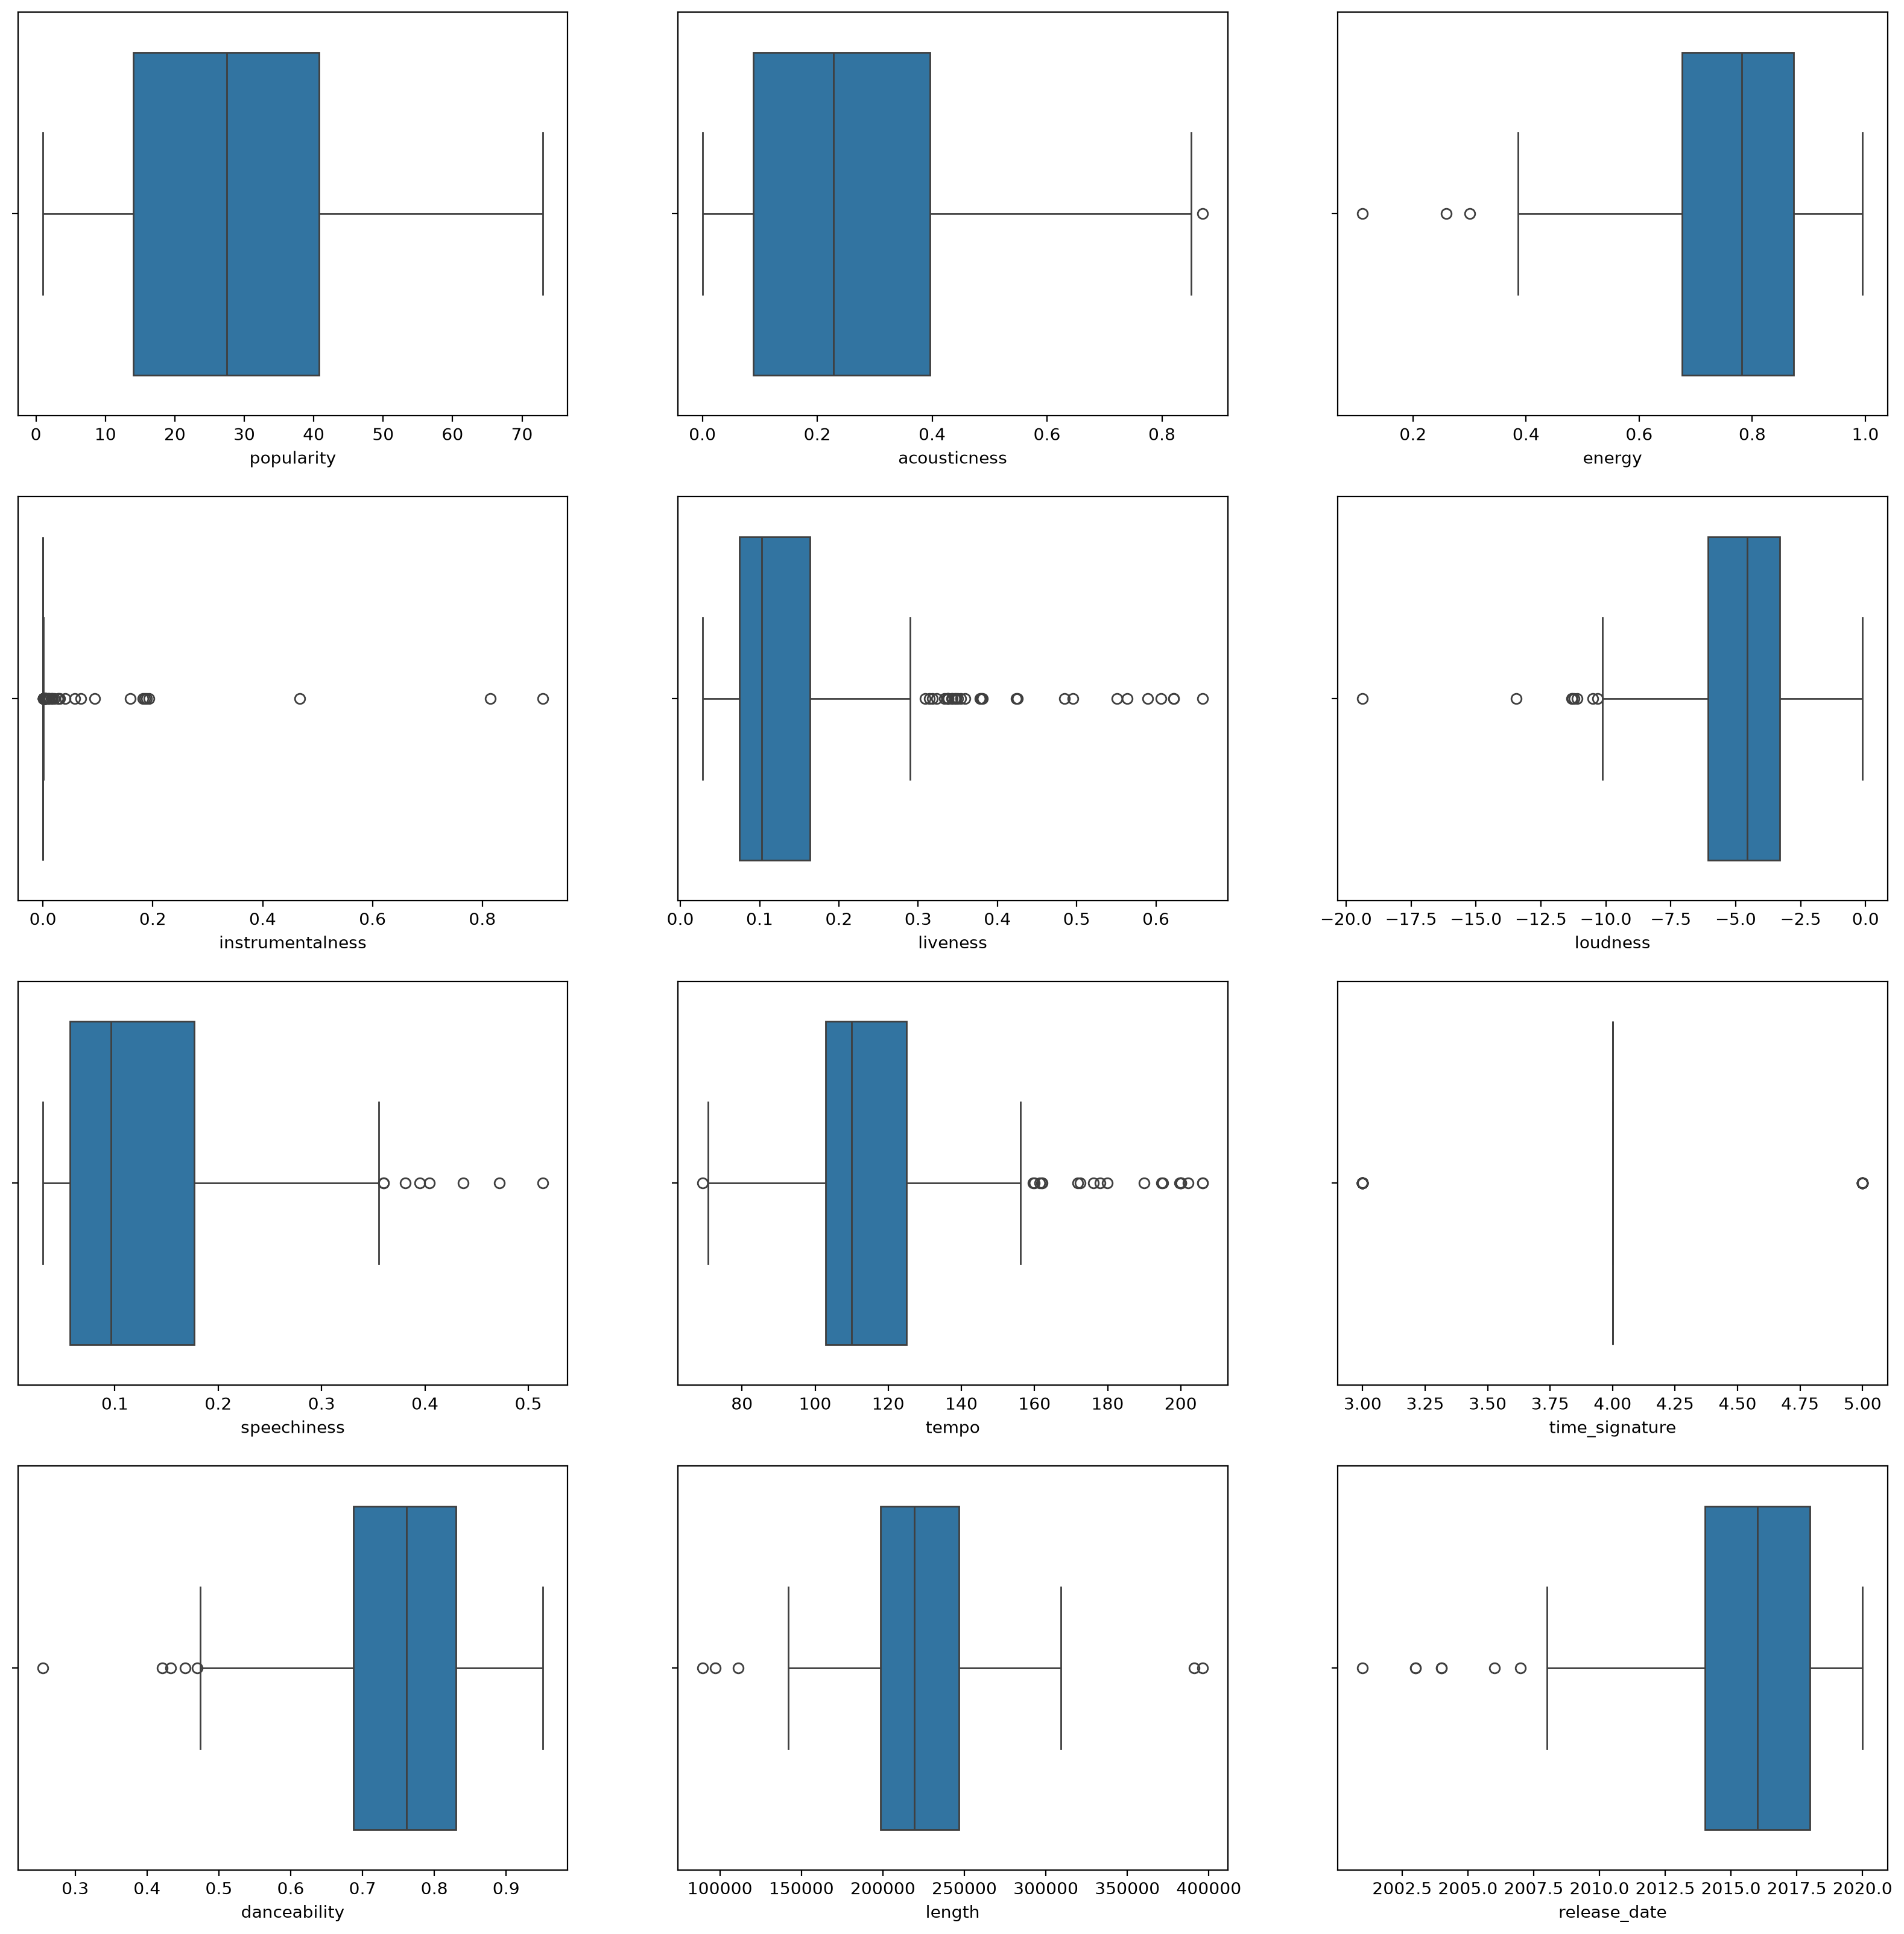

In [3]:
plt.figure(figsize=(20, 20), dpi=200)

plt.subplot(4, 3, 1)
sns.boxplot(x = "popularity", data = df)

plt.subplot(4, 3, 2)
sns.boxplot(x = "acousticness", data = df)

plt.subplot(4, 3, 3)
sns.boxplot(x = "energy", data = df)

plt.subplot(4, 3, 4)
sns.boxplot(x="instrumentalness", data = df)

plt.subplot(4, 3, 5)
sns.boxplot(x="liveness", data = df)

plt.subplot(4, 3, 6)
sns.boxplot(x="loudness", data = df)

plt.subplot(4, 3, 7)
sns.boxplot(x="speechiness", data = df)

plt.subplot(4, 3, 8)
sns.boxplot(x="tempo", data = df)

plt.subplot(4, 3, 9)
sns.boxplot(x="time_signature", data = df)

plt.subplot(4, 3, 10)
sns.boxplot(x="danceability", data = df)

plt.subplot(4, 3, 11)
sns.boxplot(x="length", data = df)

plt.subplot(4, 3, 12)
sns.boxplot(x="release_date", data = df)


In [4]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

X = df.loc[:, ('artist_top_genre', 'popularity', 'danceability', 'acousticness', 'loudness', 'energy')]
y = df['artist_top_genre']

X['artist_top_genre'] = le.fit_transform(X['artist_top_genre'])
y = le.transform(y)


In [5]:
from sklearn.cluster import KMeans

nclusters = 3
seed = 42

km = KMeans(n_clusters=nclusters, random_state=seed)
km.fit(X)

# predict the cluster for each data point

y_cluster_kmeans = km.predict(X)
print(y_cluster_kmeans)

[1 0 1 1 1 1 1 1 1 0 1 1 0 1 2 1 0 0 2 0 2 2 2 0 2 1 2 2 1 1 0 0 2 1 1 1 1
 0 0 2 1 2 1 2 1 2 2 0 0 1 0 2 2 1 1 1 1 0 0 2 0 1 1 0 1 1 0 1 0 1 1 0 0 0
 0 0 1 0 1 1 2 1 0 0 0 1 1 1 1 0 1 1 1 1 0 0 1 0 0 1 0 1 0 1 0 1 1 0 1 2 0
 0 1 0 0 1 1 1 1 1 1 1 2 0 0 0 0 2 0 1 0 1 0 1 1 1 2 1 0 0 0 1 0 2 0 1 1 0
 0 0 2 0 1 1 1 0 0 2 0 1 0 0 0 0 1 2 2 2 0 2 2 2 2 2 2 1 2 0 2 2 0 2 2 1 2
 2 0 0 1 2 1 1 2 1 1 0 0 2 0 0 2 2 0 2 1 2 0 2 1 2 2 1 1 1 0 0 0 0 0 2 1 1
 1 1 1 0 0 0 0 0 1 1 0 0 2 0 0 0 2 1 1 1 0 0 2 2 0 0 1 2 2 2 2 2 1 2 2 1 0
 0 0 1 1 1 0 1 0 1 0 0 0 2 1 1 1 0 1 0 2 0 1 0 0 0 1 0]


In [6]:
from sklearn import metrics

score = metrics.silhouette_score(X, y_cluster_kmeans)
print(score)

0.5466747351275563


In [7]:
# test different K values
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, n_init=10, init="k-means++", random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

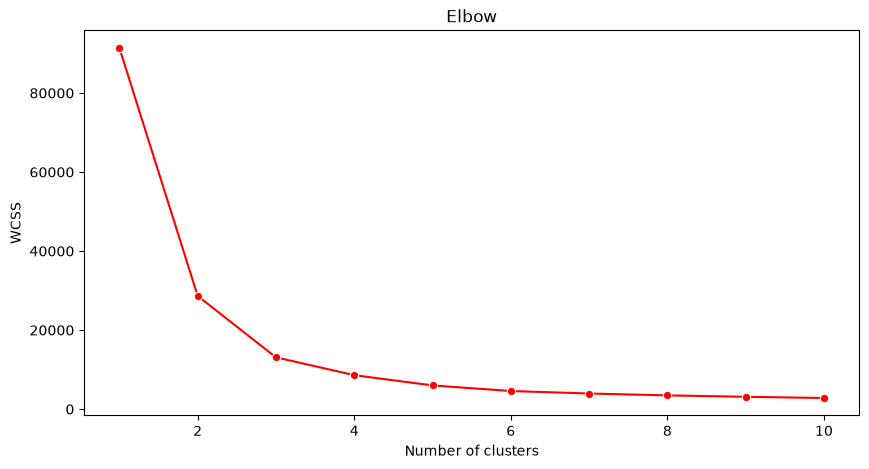

In [8]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=range(1, 11), y=wcss, marker='o', color='red')
plt.title("Elbow")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

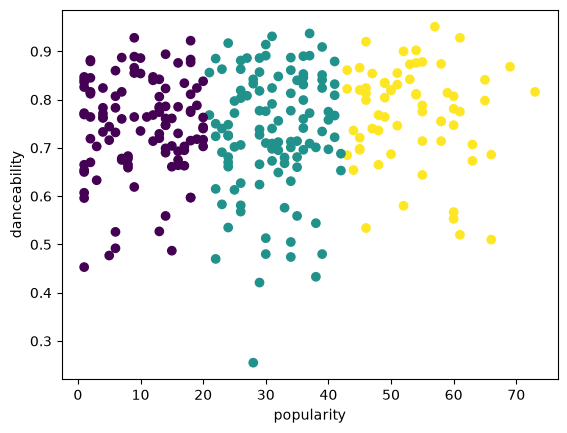

In [9]:
kmeans = KMeans(n_clusters=3, n_init=10, init="k-means++", random_state=42)
kmeans.fit(X)
labels = kmeans.predict(X)
plt.scatter(df['popularity'], df['danceability'], c = labels)
plt.xlabel('popularity')
plt.ylabel('danceability')
plt.show()